In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('../Data/Raw/loan_approval_dataset.csv')
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
df.columns.tolist()

['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

## Data Cleaning : Column Names

The raw CSV has leading whitespace in every column name except 'loan_id'. This needs to be stripped before the column can be referenced normally.

In [4]:
df.columns = df.columns.str.strip()
df.columns.tolist()

['loan_id',
 'no_of_dependents',
 'education',
 'self_employed',
 'income_annum',
 'loan_amount',
 'loan_term',
 'cibil_score',
 'residential_assets_value',
 'commercial_assets_value',
 'luxury_assets_value',
 'bank_asset_value',
 'loan_status']

In [5]:
df['education'].unique()

array([' Graduate', ' Not Graduate'], dtype=object)

## Data Cleaning: Categorical Values

Text columns (`education`, `self_employed`, `loan_status`) also contain leading whitespace in their values, consistent with the column header issue. Stripping whitespace from all string-type columns at once.

In [6]:
df = df.apply(lambda col: col.str.strip() if col.dtype == 'object' else col)
df['education'].unique()

array(['Graduate', 'Not Graduate'], dtype=object)

In [7]:
print(df['self_employed'].unique())
print(df['loan_status'].unique())

['No' 'Yes']
['Approved' 'Rejected']


## Data Cleaning: Negative Asset Values

The raw data contains negative valies in 'residential_asset_value', which don't make logical sense for an asset value. Checking summary statistics before deciding how to handle them.

In [8]:
df['residential_assets_value'].describe()

count    4.269000e+03
mean     7.472617e+06
std      6.503637e+06
min     -1.000000e+05
25%      2.200000e+06
50%      5.600000e+06
75%      1.130000e+07
max      2.910000e+07
Name: residential_assets_value, dtype: float64

In [11]:
negative_assets = df[df['residential_assets_value'] < 0]

print(negative_assets['residential_assets_value'].value_counts())
print(len(negative_assets))

print("Rows with negative values", len(negative_assets))
print("Total rows in dataset:", len(df))

residential_assets_value
-100000    28
Name: count, dtype: int64
28
Rows with negative values 28
Total rows in dataset: 4269


## Data Cleaning: Negative Asset Values (Resolved)

The Kaggle data dictionary confirms 'residential_assets_value' represents the estimated value of residential assets owned by the applicant, not a market price. This means 0 is a valid value (the applicant owns no residential assets). The 28 rows containing -100000 are treated as placeholder/error and replaced with 0.

In [17]:
df['residential_assets_value'] = df['residential_assets_value'].replace(-100000, 0)
df['residential_assets_value'].describe()

count    4.269000e+03
mean     7.473272e+06
std      6.502878e+06
min      0.000000e+00
25%      2.200000e+06
50%      5.600000e+06
75%      1.130000e+07
max      2.910000e+07
Name: residential_assets_value, dtype: float64

## Data Cleaning: Missing Values and Duplicates Check

Checking for any missing values or duplicate rows before proceeding to exploratory analysis

In [18]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64
Duplicate rows: 0


In [19]:
df.dtypes

loan_id                      int64
no_of_dependents             int64
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object

In [20]:
df.to_csv('../Data/processed/loan_approval_cleaned.csv', index = False)

## Exploratory Data Analysis

## Target Variable Distribution

Before analyzing approval patterns across applicant characteristics, check the overall balance of approved vs rejected applications.

In [24]:
print(df['loan_status'].value_counts())
df['loan_status'].value_counts(normalize = True)

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


loan_status
Approved    0.62216
Rejected    0.37784
Name: proportion, dtype: float64

In [25]:
df.groupby('loan_status')['cibil_score'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Approved,2656.0,703.461973,125.249016,300.0,618.0,711.0,803.0,900.0
Rejected,1613.0,429.468072,78.401752,300.0,364.0,429.0,493.0,885.0


### FINDINGS : CIBIL Score Strongly Seperates Approved and Rejected Applicants

Approved applicants have a mean CIBIL score of 703, while rejected applicants average 429, a gap roughtly 274 points. The 75th percentile CIBIL score for rejected applicants (493) is still lower than the 25th percentile for approved applicants (618), meaning there is very little overlap between the two groups. This suggests CIBIL score is likely the dominant factor driving approval decision in this dataset.

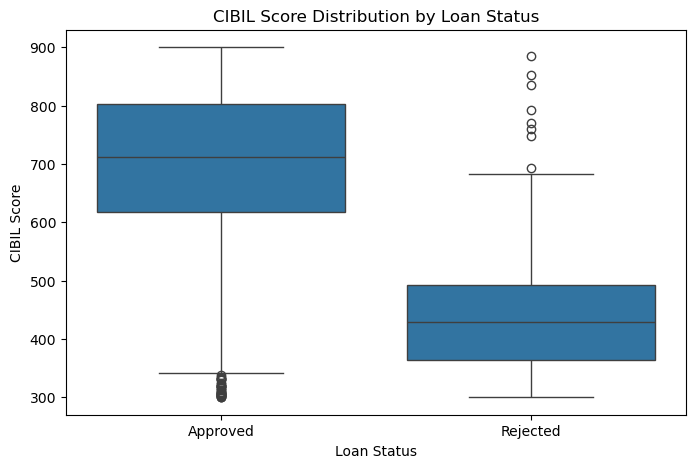

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (8,5))
sns.boxplot(data = df, x = 'loan_status', y = 'cibil_score')
plt.title('CIBIL Score Distribution by Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('CIBIL Score')
plt.show()

The boxplot confirms minimal overlap between the two groups. A small number of outliers exist in both directions, some low-CIBIL applicants were still approved, and some high-CIBIL applicants were still rejected. These execptioons are worth investigating later, sine they may reveal cases where factors other than CIBIL score meaningfully influenced the decision

In [27]:
df.groupby('loan_status')['income_annum'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Approved,2656.0,5.025904e+06,2.827228e+06,200000.0,2600000.0,5000000.0,7500000.0,9900000.0
Rejected,1613.0,5.113825e+06,2.772946e+06,200000.0,2800000.0,5100000.0,7500000.0,9900000.0


### FINDINGS: Annual Income Shows No Meaningful Relationship With Approval

Unlike CIBIL score, annual income is nearly identical between approved (mean 5,025,904) and rejected (mean 5,113,825) applicants, with almost no difference across the min, median, or max values either. this suggests income alobe does not meaningfully influence approval outcome in this dataset contrasting sharply with CIBIL score's strong separation. 

In [28]:
df.groupby('loan_status')['loan_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Approved,2656.0,1.524725e+07,9.221696e+06,300000.0,7500000.0,14600000.0,22100000.0,39500000.0
Rejected,1613.0,1.494606e+07,8.741390e+06,300000.0,7900000.0,14500000.0,20800000.0,38200000.0


### FINDINGS: Loan Amount Alone Shows No Clear Relationship with Approval

Similiar to income, loan amount shows minimal difference between approved (mean 15,247,250) and rejected (mean 14,946,060) applicants. this suggests loan amount in isolation isn't a strong predictor either. A more meaningful angle may be the loan amount relative to income (a debt-to-income stule ratio), rather than either figure alone.

## Loan Amount to Income Ratio

Since income and loan amount individually showed no clear relationship with approvalm checking whether the ratio between them (a debt-to-income style measure) reveals a pattern that neither factor showed on its onw. 

In [29]:
df['loan_to_income_ratio'] = df['loan_amount'] / df['income_annum']
df.groupby('loan_status')['loan_to_income_ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Approved,2656.0,3.025512,0.592377,1.5,2.513074,3.049691,3.544591,4.0
Rejected,1613.0,2.917779,0.594736,1.5,2.411765,2.875000,3.428571,4.0


## Approval Rate by Education

Checking whether education level (Graduate vs Not Graduate) shows a meaningful difference in approval rate

In [31]:
pd.crosstab(df['education'], df['loan_status'], normalize = 'index')

loan_status,Approved,Rejected
education,,
Graduate,0.624534,0.375466
Not Graduate,0.619765,0.380235


## FINDINGS: Education Level Shows No Meaningful Relationship with Approval

Approval rates are nearly identical between Graduates (62.5%) and Not Graduates (62.0%) a difference of less than 1% point. This suggests education level has no meaningful influence on approval outcome in this dataset

In [32]:
pd.crosstab(df['self_employed'], df['loan_status'], normalize = 'index')

loan_status,Approved,Rejected
self_employed,,
No,0.621992,0.378008
Yes,0.622326,0.377674


## FINDINGS: Self-Employment Status Shows No Relationship with Approval

Approval rates are virtually identical between non-self-employed (62.20%) and self-employed (62.23%) applicants. This factor shows no meaningful influence on approval outcome in this dataset.

## Approval Rate by Asset Values

Checking whether any of the four asset categories (residential, commercial, luxury, bank) show a meaningful relationship with approval, similiar to how CIBIL score did.

In [33]:
asset_columns = ['residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
df.groupby('loan_status')[asset_columns].mean()

,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
loan_status,,,,
Approved,7.400414e+06,5.001355e+06,1.501660e+07,4.959526e+06
Rejected,7.593242e+06,4.926720e+06,1.530694e+07,5.004960e+06


### FINDINGS: Asset Values Show No Meaningful Relationship with Approval

All four asset categories (residential, commercial, luxury, bank show nearly identical average between approved and rejected applicants. None of these factors appear to meaningfully influence approval outcome in this dataset, consistent with pattern seen in income and loan amount)